In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"D:\Data-Analytics-Project\Superstore_Data_Analytics\sample-superstore.csv", encoding="latin1")

In [ ]:
#Data Analysis

In [4]:
print(df.head)

<bound method NDFrame.head of       Row ID        Order ID  Order Date   Ship Date       Ship Mode  \
0          1  CA-2017-152156  08-11-2017  11-11-2017    Second Class   
1          2  CA-2017-152156  08-11-2017  11-11-2017    Second Class   
2          3  CA-2017-138688  12-06-2017  16-06-2017    Second Class   
3          4  US-2016-108966  11-10-2016  18-10-2016  Standard Class   
4          5  US-2016-108966  11-10-2016  18-10-2016  Standard Class   
...      ...             ...         ...         ...             ...   
9795    9796  CA-2017-125920  21-05-2017  28-05-2017  Standard Class   
9796    9797  CA-2016-128608  12-01-2016  17-01-2016  Standard Class   
9797    9798  CA-2016-128608  12-01-2016  17-01-2016  Standard Class   
9798    9799  CA-2016-128608  12-01-2016  17-01-2016  Standard Class   
9799    9800  CA-2016-128608  12-01-2016  17-01-2016  Standard Class   

     Customer ID     Customer Name    Segment        Country             City  \
0       CG-12520       C

In [5]:
print("Dataset shape:" , df.shape)

Dataset shape: (9800, 18)


In [6]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')


In [7]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [8]:
print("\nDuplicate Values:")
print(df.duplicated().sum())


Duplicate Values:
0


In [9]:
print("\n Data Information:")
df.info()
      


 Data Information:
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtyp

In [11]:
#Clean The DataSet

In [12]:
df.columns = df.columns.str.strip()

In [13]:
df.drop_duplicates(inplace=True)

In [19]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [20]:
print(df["Order Date"].head(10))

0    08-11-2017
1    08-11-2017
2    12-06-2017
3    11-10-2016
4    11-10-2016
5    09-06-2015
6    09-06-2015
7    09-06-2015
8    09-06-2015
9    09-06-2015
Name: Order Date, dtype: str


In [21]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed",
    errors="coerce"
)

In [22]:
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed",
    errors="coerce"
)

In [23]:
print("Date conversion completed!")

Date conversion completed!


In [24]:
print(df[["Order Date","Ship Date"]].head())

  Order Date  Ship Date
0 2017-08-11 2017-11-11
1 2017-08-11 2017-11-11
2 2017-12-06 2017-06-16
3 2016-11-10 2016-10-18
4 2016-11-10 2016-10-18


In [25]:
#calculate business KPIs

In [26]:
total_sales = df["Sales"].sum()

In [28]:
print("Total Sales:", round(total_sales,2))

Total Sales: 2261536.78


In [32]:
total_orders = df["Order ID"].sum()

In [33]:
print("Total Orders:", total_orders)

Total Orders: CA-2017-152156CA-2017-152156CA-2017-138688US-2016-108966US-2016-108966CA-2015-115812CA-2015-115812CA-2015-115812CA-2015-115812CA-2015-115812CA-2015-115812CA-2015-115812CA-2018-114412CA-2017-161389US-2016-118983US-2016-118983CA-2015-105893CA-2015-167164CA-2015-143336CA-2015-143336CA-2015-143336CA-2017-137330CA-2017-137330US-2018-156909CA-2016-106320CA-2017-121755CA-2017-121755US-2016-150630US-2016-150630US-2016-150630US-2016-150630US-2016-150630US-2016-150630US-2016-150630CA-2018-107727CA-2017-117590CA-2017-117590CA-2016-117415CA-2016-117415CA-2016-117415CA-2016-117415CA-2018-120999CA-2017-101343CA-2018-139619CA-2017-118255CA-2017-118255CA-2015-146703CA-2017-169194CA-2017-169194CA-2016-115742CA-2016-115742CA-2016-115742CA-2016-115742CA-2017-105816CA-2017-105816CA-2017-111682CA-2017-111682CA-2017-111682CA-2017-111682CA-2017-111682CA-2017-111682CA-2017-111682CA-2016-135545CA-2016-135545CA-2016-135545CA-2016-135545US-2016-164175CA-2015-106376CA-2015-106376CA-2017-119823CA-201

In [34]:
total_customers = df["Customer ID"].nunique()

In [35]:
print("Total_customers",total_customers)

Total_customers 793


In [36]:
#verification

In [37]:
print("Dataset Shape:",df.shape)

Dataset Shape: (9800, 18)


In [39]:
print("Column Names:")
      

Column Names:


In [40]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [41]:
print("Missing Values:")

Missing Values:


In [42]:
print(df.isnull().sum())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [44]:
print("Duplicate Rows:",df.duplicated().sum())

Duplicate Rows: 0


In [47]:
category_sales = df.groupby("Category")["Sales"].sum()

In [48]:
plt.figure(figsize=(9,5))

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Axes: xlabel='Category'>

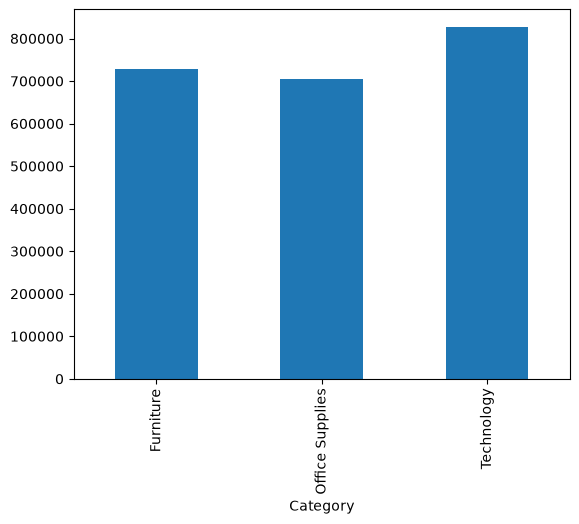

In [49]:
category_sales.plot(kind="bar")

Text(0, 0.5, 'Total Sales')

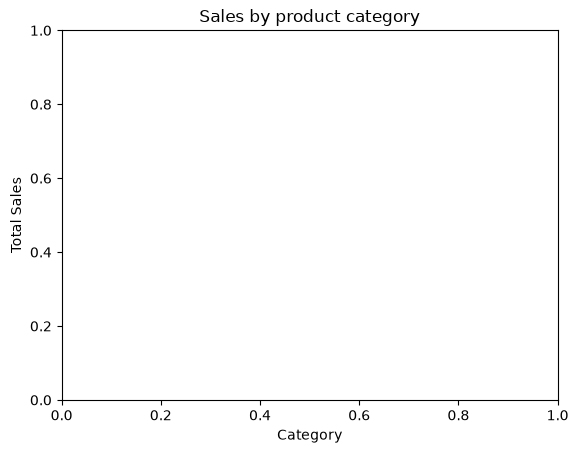

In [51]:
plt.title("Sales by product category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

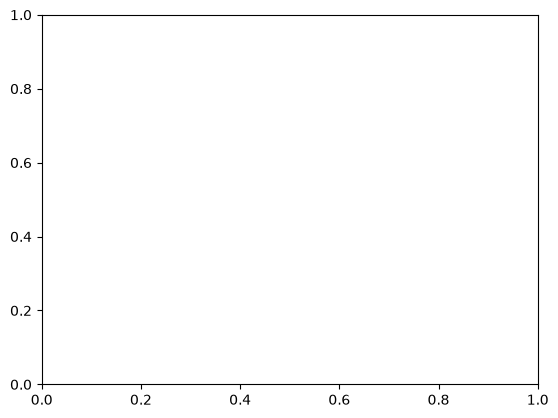

In [52]:
plt.xticks(rotation=0)

In [53]:
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [54]:
plt.show()

In [55]:
df["Year_Month"] = (
    df["Order Date"].dt.to_period("M").astype(str)
)


In [56]:
monthly_sales = (
    df.groupby("Year_Month")["Sales"].sum()
)

In [57]:
plt.figure(figsize=(12,5))

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

<Axes: xlabel='Year_Month'>

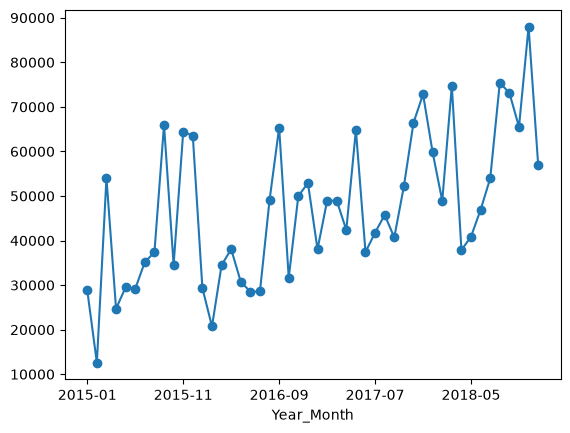

In [58]:
monthly_sales.plot(kind="line", marker="o")


Text(0, 0.5, 'Sales')

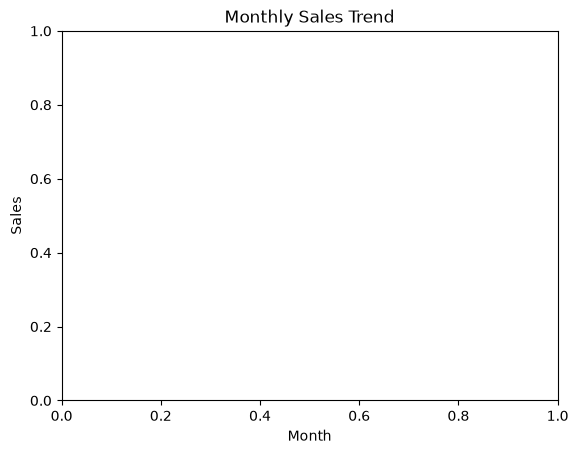

In [59]:
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")


(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

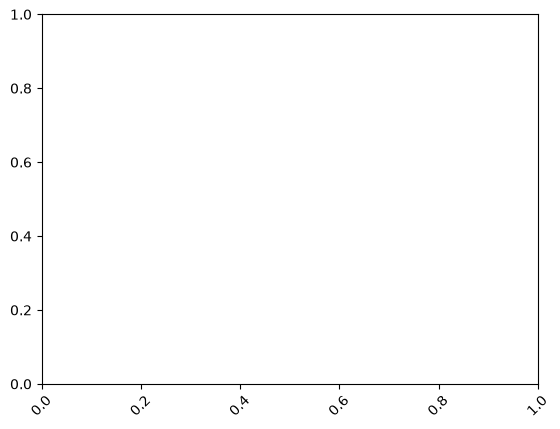

In [60]:
plt.xticks(rotation=45)

In [61]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [62]:
import os



In [65]:
import os


In [71]:
save_path == r"D:\Data-Analytics-Project\Superstore_Data_Analytics\Cleaned",exist_ok == True
os.makedirs(save_path,exist_ok=True)

NameError: name 'save_path' is not defined

In [67]:
print(os.getcwd())

C:\Users\Dell


In [72]:
import os

# Define the folder where you want to save the file
save_path = r"D:\Data-Analytics-Project\Superstore_Data_Analytics\Cleaned"

# Create the folder if it doesn't exist
os.makedirs(save_path, exist_ok=True)

# Define the CSV file path
file_path = os.path.join(save_path, "Superstore_Cleaned.csv")

# Save the cleaned dataset
df.to_csv(file_path, index=False)

# Confirmation
print("Dataset saved successfully!")
print("File location:", file_path)

Dataset saved successfully!
File location: D:\Data-Analytics-Project\Superstore_Data_Analytics\Cleaned\Superstore_Cleaned.csv
